In [1]:
# use SQL
import sqlite3

In [2]:
# Create dataset
conn = sqlite3.connect('churn.db')

In [3]:
# Export pandas dataframe into SQL table
import pandas as pd
# load data
data = pd.read_csv('./data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
data.to_sql('churn', conn, if_exists='replace', index=False)

FileNotFoundError: [Errno 2] No such file or directory: './data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [22]:
# SQL Q1.Churn rate by contract type
query1 = '''
SELECT Contract,
       COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn='Yes' THEN 1 ELSE 0 END) AS churned_customers
  FROM churn
  GROUP BY Contract
'''
result1 = pd.read_sql(query1, conn)
result1

,Contract,total_customers,churned_customers
0,Month-to-month,3875,1655
1,One year,1473,166
2,Two year,1695,48


<function matplotlib.pyplot.show(close=None, block=None)>

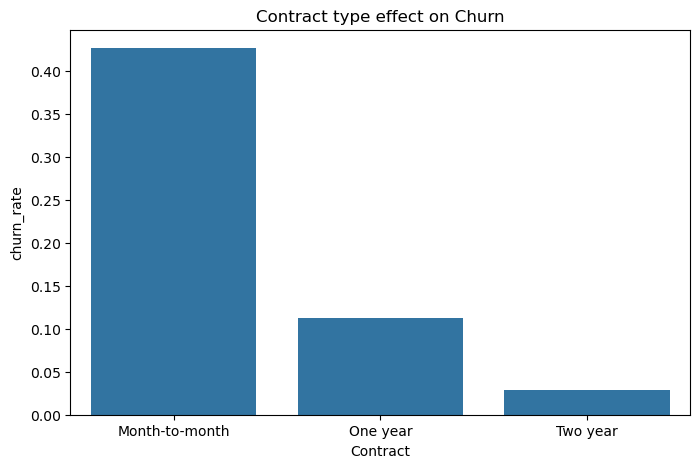

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
result1['churn_rate'] = result1['churned_customers']/result1['total_customers']
plt.figure(figsize=(8,5))
sns.barplot(
    x = 'Contract',
    y = 'churn_rate',
    data = result1
)
plt.title('Contract type effect on Churn')
plt.show

In [24]:
# Customers on month-to-month contracts represent the highest retention risk group and 
# should be prioritised for targeted retention strategies.

In [25]:
# SQL Q2. Average monthly charges by churn
query2 = '''
SELECT Churn,
       AVG(MonthlyCharges),
       MIN(MonthlyCharges),
       MAX(MonthlyCharges)
 FROM churn
 GROUP BY Churn
'''
result = pd.read_sql(query2, conn)
result

,Churn,AVG(MonthlyCharges),MIN(MonthlyCharges),MAX(MonthlyCharges)
0,No,61.265124,18.25,118.75
1,Yes,74.441332,18.85,118.35


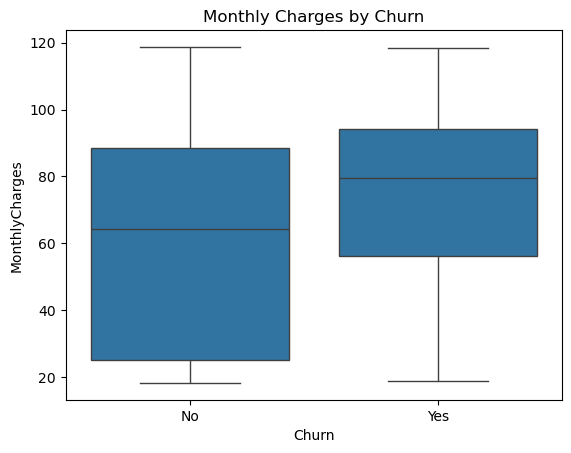

In [26]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=data)

plt.title("Monthly Charges by Churn")
plt.show()

In [27]:
# SQL Q3. Churn by paymentmethod
query3 = '''
SELECT PaymentMethod,
       AVG(CASE WHEN Churn='Yes' THEN 1 ELSE 0 END)*100 as churn_rate
  FROM churn
  GROUP BY PaymentMethod
'''
result3 = pd.read_sql(query3, conn)
result3

,PaymentMethod,churn_rate
0,Bank transfer (automatic),16.709845
1,Credit card (automatic),15.243101
2,Electronic check,45.285412
3,Mailed check,19.106700


<function matplotlib.pyplot.show(close=None, block=None)>

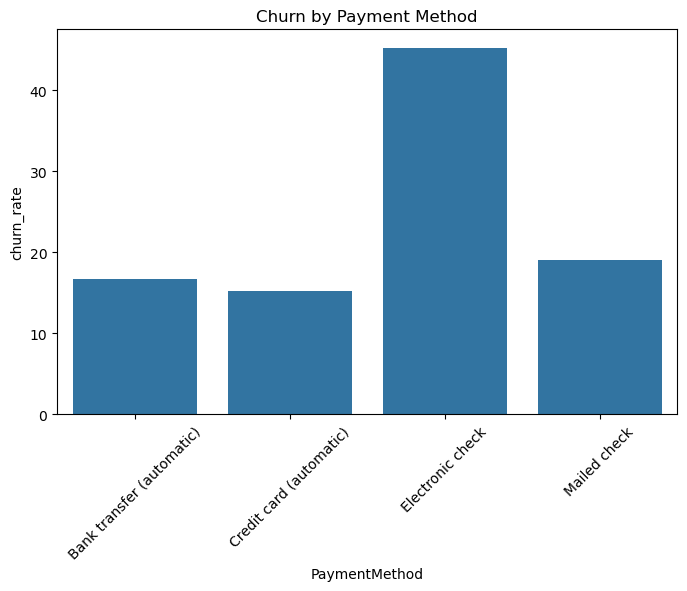

In [28]:
plt.figure(figsize=(8,5))
sns.barplot(
    x = 'PaymentMethod',
    y = 'churn_rate',
    data = result3
)
plt.xticks(rotation = 45)
plt.title('Churn by Payment Method')
plt.show


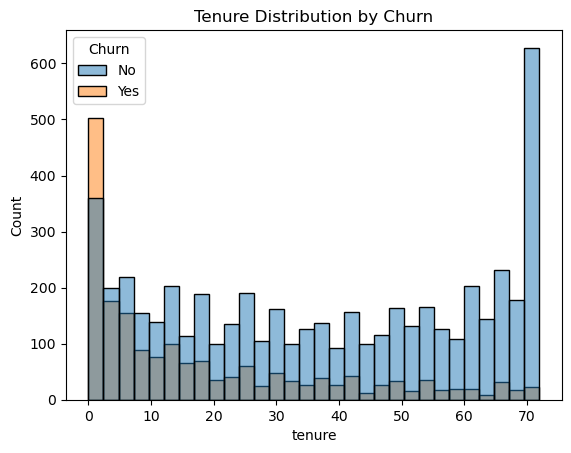

In [29]:
sns.histplot(data=data, x="tenure", hue="Churn", bins=30)

plt.title("Tenure Distribution by Churn")
plt.show()

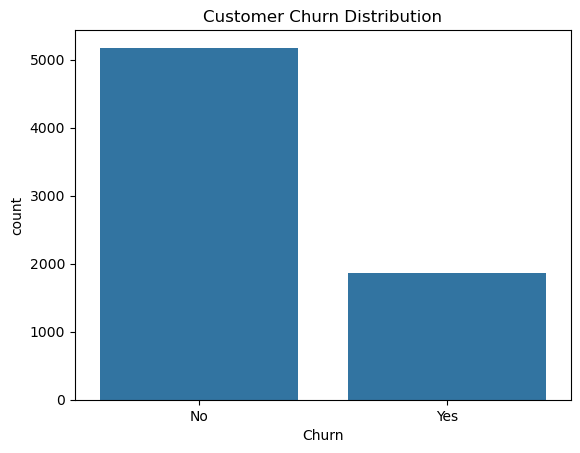

In [30]:
sns.countplot(x="Churn", data=data)
plt.title("Customer Churn Distribution")
plt.show()

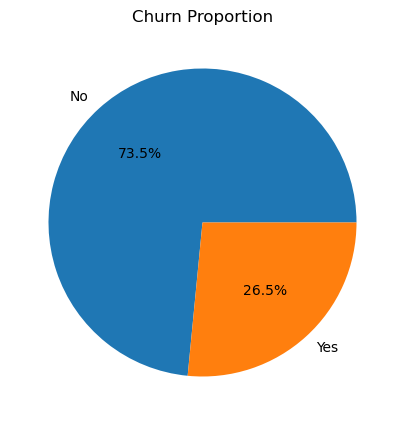

In [31]:
data["Churn"].value_counts().plot.pie(
    autopct='%1.1f%%',
    figsize=(5,5)
)

plt.title("Churn Proportion")
plt.ylabel("")
plt.show()